# Linear Regression
Predict a house's `SalePrice` from its features, implementing linear regression **from scratch with NumPy** and gradient descent.

> Remember to **File → Save a copy in Drive** before editing.

# Import the required libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)  # reproducible random weight initialisation

## Data Preprocessing

### **Exploring the dataset**

Let's start with loading the training data from the csv into a pandas dataframe

Load the datasets from GitHub. Train dataset has already been loaded for you in df below. To get test dataset use the commented code.

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/train_processed_splitted.csv')

Let's see what the first 5 rows of this dataset looks like

In [3]:
df.head()

,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,Utilities,SalePrice
0,11553,1051,1159,336,0,5,AllPub,158000
1,8400,1052,1052,288,0,5,AllPub,138500
2,8960,1008,1028,360,0,6,AllPub,115000
3,11100,0,930,308,0,7,AllPub,84900
4,15593,1304,2287,667,0,4,AllPub,225000


What are all the features present? What is the range for each of the features along with their mean?

In [4]:
print("Shape (rows, columns):", df.shape)
print("\nFeatures:", list(df.columns))
print("\nData types:\n", df.dtypes)
print("\nMissing values per column:\n", df.isna().sum())

# count, mean, std, min, quartiles, max for every numeric feature
summary = df.describe().T[['mean', 'min', 'max']]
summary['range'] = summary['max'] - summary['min']
summary

Shape (rows, columns): (1314, 8)

Features: ['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'PoolArea', 'OverallCond', 'Utilities', 'SalePrice']

Data types:
 LotArea         int64
TotalBsmtSF     int64
GrLivArea       int64
GarageArea      int64
PoolArea        int64
OverallCond     int64
Utilities      object
SalePrice       int64
dtype: object

Missing values per column:
 LotArea        0
TotalBsmtSF    0
GrLivArea      0
GarageArea     0
PoolArea       0
OverallCond    0
Utilities      0
SalePrice      0
dtype: int64


,mean,min,max,range
LotArea,10622.104262,1300.0,215245.0,213945.0
TotalBsmtSF,1058.311263,0.0,6110.0,6110.0
GrLivArea,1512.900304,334.0,5642.0,5308.0
GarageArea,473.480213,0.0,1418.0,1418.0
PoolArea,2.643075,0.0,738.0,738.0
OverallCond,5.582192,1.0,9.0,8.0
SalePrice,180795.504566,34900.0,755000.0,720100.0


In [5]:
# Categorical feature: which categories exist, and how often?
df['Utilities'].value_counts()

,count
Utilities,
AllPub,1313
NoSeWa,1


**Observations**
- There are **7 input features** (`LotArea`, `TotalBsmtSF`, `GrLivArea`, `GarageArea`, `PoolArea`, `OverallCond`, `Utilities`) and the target **`SalePrice`**.
- `Utilities` is categorical (text), the rest are numeric.
- The features live on wildly different scales (e.g. `LotArea` is in the thousands/hundreds of thousands, `OverallCond` is 1–9), which is why we need scaling.

### **Feature Scaling and One-Hot Encoding**

You must have noticed that some features `(such as Utilities)` are not continuous values.

These features contain values indicating different categories and must somehow be converted to numbers so that the computer can understand it. `(Computers only understand numbers and not strings)`

These features are called categorical features. We can represent these features as a `One-Hot Representation`

You must have also noticed that all the other features, each are in a different scale. This can be detremental to the performance of our linear regression model and so we normalize them so that all of them are in the range $[0,1]$

> NOTE: When you are doing feature scaling, store the min/max which you will use to normalize somewhere. This is then to be used at testing time. Try to think why are doing this?

In [6]:
# Do the one-hot encoding here
# Each category of `Utilities` becomes its own 0/1 column (Utilities_AllPub, Utilities_NoSeWa, ...)
dummies = pd.get_dummies(df['Utilities'], dtype='int32', prefix='Utilities')
df = pd.concat([df.drop('Utilities', axis=1), dummies], axis=1)
df.head()

,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,SalePrice,Utilities_AllPub,Utilities_NoSeWa
0,11553,1051,1159,336,0,5,158000,1,0
1,8400,1052,1052,288,0,5,138500,1,0
2,8960,1008,1028,360,0,6,115000,1,0
3,11100,0,930,308,0,7,84900,1,0
4,15593,1304,2287,667,0,4,225000,1,0


In [7]:
# Do the feature scaling here  (min-max scaling to [0, 1])
# Continuous columns = every column that is NOT a 0/1 one-hot column. SalePrice is scaled too.
dummy_cols = list(dummies.columns)
cols_to_scale = [c for c in df.columns if c not in dummy_cols]

# Store the TRAIN min / max so exactly the same transformation can be applied to the test set
min_vals = df[cols_to_scale].min()
max_vals = df[cols_to_scale].max()
range_vals = (max_vals - min_vals).replace(0, 1)   # guard against division by zero

df[cols_to_scale] = (df[cols_to_scale] - min_vals) / range_vals

print("Stored min values:\n", min_vals, "\n\nStored max values:\n", max_vals)
df[cols_to_scale].describe().loc[['min', 'max']]

Stored min values:
 LotArea         1300
TotalBsmtSF        0
GrLivArea        334
GarageArea         0
PoolArea           0
OverallCond        1
SalePrice      34900
dtype: int64 

Stored max values:
 LotArea        215245
TotalBsmtSF      6110
GrLivArea        5642
GarageArea       1418
PoolArea          738
OverallCond         9
SalePrice      755000
dtype: int64


,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,SalePrice
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Why store min/max?** At test time the model must see inputs transformed *exactly* the way the training inputs were, otherwise the learned weights are applied to numbers on a different scale and predictions are meaningless. It also avoids *data leakage*: the test set is meant to mimic unseen data, so its statistics must not influence preprocessing. The same min/max are used later to convert predictions back into real dollars.

### **Conversion to NumPy**

Ok so now that we have all preprocessed all the data, we need to convert it to numpy for our linear regression model

Assume that our dataset has a total of $N$ datapoints. Each datapoint having a total of $D$ features (after one-hot encoding), we want our numpy array to be of shape $(N, D)$

In our task, we have to predict the `SalePrice`. We will need 2 numpy arrays $(X, Y)$. These represent the features and targets respectively

In [8]:
# Convert to numpy array
x = df.drop('SalePrice', axis=1).to_numpy(dtype=float)           # (N, D)
y = df['SalePrice'].to_numpy(dtype=float).reshape(-1, 1)          # (N, 1)

N, D = x.shape
print("x shape:", x.shape, "| y shape:", y.shape)
print("Feature order:", list(df.drop('SalePrice', axis=1).columns))

x shape: (1314, 8) | y shape: (1314, 1)
Feature order: ['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'PoolArea', 'OverallCond', 'Utilities_AllPub', 'Utilities_NoSeWa']


## Linear Regression formulation

We now have our data in the form we need. Let's try to create a linear model to get our initial (Really bad) prediction

Let's say a single datapoint in our dataset consists of 3 features $(x_1, x_2, x_3)$, we can pose it as a linear equation as follows:
$$ y = w_1x_1 + w_2x_2 + w_3x_3 + b $$
Here we have to learn 4 parameters $(w_1, w_2, w_3, b)$

Now how do we extend this to multiple datapoints?

Try to answer the following:
- How many parameters will we have to learn in the cae of our dataset? (Don't forget the bias term)
- Form a linear equation for our dataset. We need just a single matrix equation which correctly represents all the datapoints in our dataset
- Implement the linear equation as an equation using NumPy arrays (Start by randomly initializing the weights from a standard normal distribution)

In [9]:
print(f"Number of features D = {D}")
print(f"Number of parameters to learn = D weights + 1 bias = {D + 1}")

Number of features D = 8
Number of parameters to learn = D weights + 1 bias = 9


**Answers**

- **Number of parameters:** one weight per feature plus one bias → $D + 1$ (printed above; with the 6 numeric features + 2 one-hot `Utilities` columns that is 8 + 1 = 9).
- **Matrix equation** for all $N$ datapoints at once, with $X\in\mathbb{R}^{N\times D}$, $W\in\mathbb{R}^{1\times D}$ and bias $b$ (broadcast to every row):

$$\hat{Y} = X W^{T} + b \qquad (N\times1)$$

  Equivalently, appending a column of ones to $X$ and folding $b$ into the weights: $\hat Y = \tilde X\,\tilde W^{T}$.
- **NumPy implementation** below, with weights drawn from a standard normal distribution.

In [10]:
# Randomly initialise the weights from a standard normal distribution
w = np.random.randn(1, D)     # (1, D)
b = np.random.randn(1)        # scalar bias (shape (1,)), broadcast over all rows

y_pred = x @ w.T + b          # (N, D) @ (D, 1) + (1,) -> (N, 1)
print("y_pred shape:", y_pred.shape)

y_pred shape: (1314, 1)


How well does our model perform? Try comparing our predictions with the actual values

In [11]:
def to_dollars(arr_scaled):
    """Undo the min-max scaling of SalePrice (scaled -> original dollars)."""
    return arr_scaled * range_vals['SalePrice'] + min_vals['SalePrice']

idx_init = np.random.randint(0, N, 5)
print("Predicted SalePrice:", to_dollars(y_pred[idx_init]).round().astype(int).squeeze().tolist())
print("Actual SalePrice:   ", to_dollars(y[idx_init]).round().astype(int).squeeze().tolist())

Predicted SalePrice: [1193685, 1074239, 1328713, 1209386, 1158724]
Actual SalePrice:    [159950, 177000, 240000, 129500, 179540]


With random weights the predictions are essentially random numbers, unrelated to the actual prices, so the model performs terribly. We now need a way to *measure* how wrong it is (a loss) and *improve* the weights.

### **Learning weights using gradient descent**

So these results are really horrible. We need to somehow update our weights so that it correclty represents our data. How do we do that?

We must do the following:
- We need some numerical indication for our performance, for this we define a Loss Function ( $\mathscr{L}$ )
- Find the gradients of the `Loss` with respect to the `Weights`
- Update the weights in accordance to the gradients: $W = W - \alpha\nabla_W \mathscr{L}$

Lets define the loss function:
- We will use the MSE loss since it is a regression task. (Specify the assumptions we make while doing so as taught in the class).
- Implement this loss as a function. (Use numpy as much as possible)

**Assumptions behind using MSE**
1. **Linearity:** the target is a linear function of the features plus noise.
2. **Gaussian noise:** errors are normally distributed with zero mean. Under this assumption, minimising MSE is exactly *maximum-likelihood estimation*.
3. **Homoscedasticity:** the error variance is constant across all inputs.
4. **Independence:** errors of different datapoints are independent.
5. **No (severe) outliers / no multicollinearity:** squaring errors makes MSE sensitive to outliers, and strongly correlated features make weights unstable.

$$\mathscr{L}=\frac1N\sum_{i=1}^{N}(\hat y_i-y_i)^2$$

In [12]:
def mse_loss_fn(y_true, y_pred):
    """Mean squared error between targets and predictions."""
    return float(np.mean((y_pred - y_true) ** 2))


print("Initial (random weights) loss:", mse_loss_fn(y, y_pred))

Initial (random weights) loss: 2.0659321436641225


Calculate the gradients of the loss with respect to the weights (and biases). First write the equations down on a piece of paper, then proceed to implement it

**Derivation.** With $\hat Y = XW^T+b$ and $\mathscr{L}=\frac1N\sum_i(\hat y_i-y_i)^2$:

$$\frac{\partial\mathscr{L}}{\partial W}=\frac{2}{N}(\hat Y-Y)^{T}X \;\;(1\times D),\qquad \frac{\partial\mathscr{L}}{\partial b}=\frac{2}{N}\sum_{i=1}^{N}(\hat y_i-y_i)$$

In [13]:
def get_gradients(y_true, y_pred, W, b, X):
    """
    Calculates the gradients for the MSE loss function with respect to the weights (and bias)

    Args:
        y_true: The true values of the target variable (SalePrice in our case)
        y_pred: The predicted values of the target variable using our model (W*X + b)

        W: The weights of the model
        b: The bias of the model
        X: The input features

    Returns:
        dW: The gradients of the loss function with respect to the weights
        db: The gradients of the loss function with respect to the bias
    """
    n = X.shape[0]
    error = y_pred - y_true            # (N, 1)
    dW = (2 / n) * (error.T @ X)       # (1, D)
    db = (2 / n) * np.sum(error)       # scalar
    return dW, db

In [14]:
# Sanity check: compare analytic gradients with numerical (finite-difference) gradients
dw_a, db_a = get_gradients(y, x @ w.T + b, w, b, x)
eps = 1e-6
dw_n = np.zeros_like(w)
for j in range(D):
    w_p, w_m = w.copy(), w.copy()
    w_p[0, j] += eps; w_m[0, j] -= eps
    dw_n[0, j] = (mse_loss_fn(y, x @ w_p.T + b) - mse_loss_fn(y, x @ w_m.T + b)) / (2 * eps)
db_n = (mse_loss_fn(y, x @ w.T + (b + eps)) - mse_loss_fn(y, x @ w.T + (b - eps))) / (2 * eps)
print("Max |dW analytic - numeric|:", np.abs(dw_a - dw_n).max())
print("|db analytic - numeric|:    ", abs(db_a - db_n))

Max |dW analytic - numeric|: 2.3266599757931772e-10
|db analytic - numeric|:     2.331232984431608e-10


Update the weights using the gradients

In [15]:
def update(weights, bias, gradients_weights, gradients_bias, lr):
    """
    Updates the weights (and bias) using the gradients and the learning rate

    Args:
        weights: The current weights of the model
        bias: The current bias of the model

        gradients_weights: The gradients of the loss function with respect to the weights
        gradients_bias: The gradients of the loss function with respect to the bias

        lr: The learning rate

    Returns:
        weights_new: The updated weights of the model
        bias_new: The updated bias of the model
    """
    weights_new = weights - lr * gradients_weights
    bias_new = bias - lr * gradients_bias
    return weights_new, bias_new

Put all these together to find the loss value, its gradient and finally updating the weights in a loop. Feel free to play around with different learning rates and epochs

> NOTE: The code in comments are just meant to be used as a guide. You will have to do changes based on your code

In [16]:
NUM_EPOCHS = 1000
LEARNING_RATE = 2e-2

losses = []

for epoch in range(NUM_EPOCHS):
    y_pred = x @ w.T + b
    loss = mse_loss_fn(y, y_pred)
    losses.append(loss)
    dw, db = get_gradients(y, y_pred, w, b, x)
    w, b = update(w, b, dw, db, LEARNING_RATE)

print(f"Loss: {losses[0]:.6f} (epoch 0)  ->  {losses[-1]:.6f} (epoch {NUM_EPOCHS})")

Loss: 2.065932 (epoch 0)  ->  0.010037 (epoch 1000)


Now use matplotlib to plot the loss graph

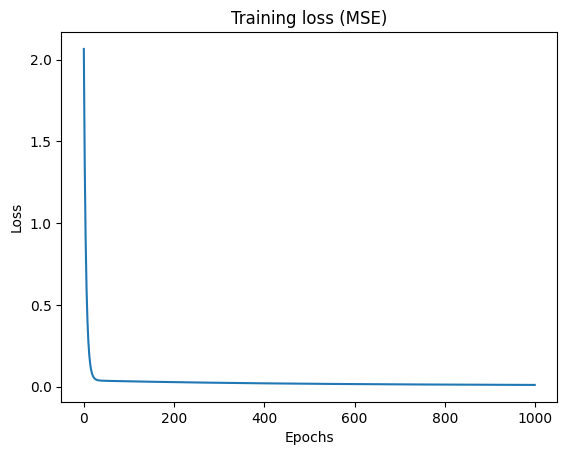

In [17]:
plt.plot(losses)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training loss (MSE)')
plt.show()

In [18]:
# Training predictions after learning, back in dollars
y_pred_train = x @ w.T + b
idx_tr = np.random.randint(0, N, 5)
print("Predicted SalePrice:", to_dollars(y_pred_train[idx_tr]).round().astype(int).squeeze().tolist())
print("Actual SalePrice:   ", to_dollars(y[idx_tr]).round().astype(int).squeeze().tolist())
print("Learned weights:", dict(zip(df.drop('SalePrice', axis=1).columns, w.ravel().round(4))))
print("Learned bias:", b.round(4))

Predicted SalePrice: [121353, 160967, 199294, 265716, 204975]
Actual SalePrice:    [107500, 126500, 215000, 206900, 202900]
Learned weights: {'LotArea': np.float64(0.425), 'TotalBsmtSF': np.float64(-0.2921), 'GrLivArea': np.float64(0.3867), 'GarageArea': np.float64(0.7331), 'PoolArea': np.float64(-0.2299), 'OverallCond': np.float64(-0.1982), 'Utilities_AllPub': np.float64(1.0311), 'Utilities_NoSeWa': np.float64(0.7725)}
Learned bias: [-1.0126]


### **Testing with test data**

Load and apply all the preprocessing steps used in the training data for the testing data as well. Remember to use the **SAME** min/max values which you used for the training set and not recalculate them from the test set. Also mention why we are doing this.

To load test data from GitHub, use the code below.

In [19]:
df_test = pd.read_csv('https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/test_processed_splitted.csv')
print(df_test)

     LotArea  TotalBsmtSF  GrLivArea  GarageArea  PoolArea  OverallCond  \
0      15623         2396       4476         813       555            5   
1      11952          808       1969         534         0            6   
2       7558          896       1913         342         0            6   
3       6762         1187       1208         632         0            5   
4       8529         1454       1434         527         0            5   
..       ...          ...        ...         ...       ...          ...   
141     9135         1536       1536         532         0            5   
142    11639         1428       1428         480         0            5   
143    11475         1584       1776         888         0            5   
144     5925          907       1131         672         0            7   
145    14559         1008       1363         288         0            7   

    Utilities  SalePrice  
0      AllPub     745000  
1      AllPub     190000  
2      AllPub     

In [20]:
# One-hot encode the test set the same way as the train set
df_test = pd.concat(
    [df_test.drop('Utilities', axis=1),
     pd.get_dummies(df_test['Utilities'], dtype='int32', prefix='Utilities')],
    axis=1)

# Let's find all the columns that are missing in the test set
missing_cols = set(df.columns) - set(df_test.columns)
print("Columns missing from the test set:", missing_cols)

# Add these columns to the test set with all zeros
# (a category that never appears in the test set, e.g. Utilities_NoSeWa, is correctly 0 everywhere)
for col in missing_cols:
    df_test[col] = 0

# Put the columns in exactly the same order as the training data (order matters for x @ w.T)
df_test = df_test[df.columns]

Columns missing from the test set: {'Utilities_NoSeWa'}


Using the weights learnt above, predict the values in the test dataset. Also answer the following questions:
- Are the predictions good?
- What is the MSE loss for the testset
- Is the MSE loss for testing greater or lower than training
- Why is this the case

In [21]:
# Fill NaN values
df_test.fillna(0, inplace=True)

# Scale features using the TRAIN min/max (NOT recomputed from the test set)
df_test[cols_to_scale] = (df_test[cols_to_scale] - min_vals) / range_vals

# Check for unexpected NaNs
assert not df_test.isna().any().any(), "Unexpected NaNs found in df_test"
print("No NaNs in test set. Scaled test range (can slightly exceed [0,1] - that is expected):")
df_test[cols_to_scale].describe().loc[['min', 'max']]

No NaNs in test set. Scaled test range (can slightly exceed [0,1] - that is expected):


,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,SalePrice
min,0.001776,0.000000,0.077807,0.000000,0.000000,0.125,0.034856
max,0.161069,0.506383,0.780332,0.735543,0.752033,1.000,0.986113


In [22]:
# Convert to numpy array
x_test = df_test.copy().drop('SalePrice', axis=1).to_numpy(dtype=float) # (N, D)
y_test = df_test.copy()['SalePrice'].to_numpy(dtype=float).reshape(-1, 1) # (N, 1)
print(x_test.shape)

extra_cols = list(set(df_test.columns) - set(df.columns))
print("Extra columns in df_test:", extra_cols)

missing_cols = list(set(df.columns) - set(df_test.columns))
print("Missing columns in df_test:", missing_cols)

(146, 8)
Extra columns in df_test: []
Missing columns in df_test: []


In [23]:
# Make predictions
y_pred_test = x_test @ w.T + b # (N, 1)
loss_test = mse_loss_fn(y_test, y_pred_test)

# Scale the predictions back to the original scale
y_pred_test_scaled = to_dollars(y_pred_test)
y_test_scaled = to_dollars(y_test)

idx = np.random.randint(0, x_test.shape[0], 5)
y_pred_test_sample = y_pred_test_scaled[idx].round().astype(int)
y_true_test_sample = y_test_scaled[idx].round().astype(int)

print('Predicted SalePrice: \t', y_pred_test_sample.squeeze().tolist())
print('Actual SalePrice: \t', y_true_test_sample.squeeze().tolist())
print('\nTest Loss: \t\t', loss_test)

Predicted SalePrice: 	 [326284, 219259, 99138, 226109, 2608]
Actual SalePrice: 	 [410000, 197500, 126000, 264132, 84500]

Test Loss: 		 0.01413905727571964


Train MSE (scaled): 0.010029
Test  MSE (scaled): 0.014139
-> Test loss is GREATER than train loss

Test RMSE: $85,625 | Test MAE: $60,551 | Test R^2: 0.189


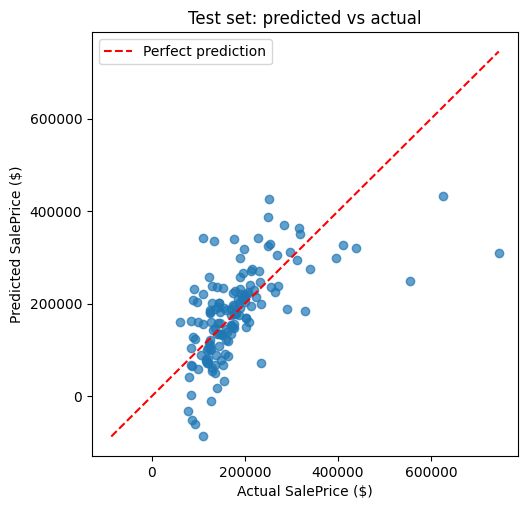

In [24]:
# Quantitative answers to the questions above
loss_train = mse_loss_fn(y, x @ w.T + b)

ss_res = np.sum((y_test_scaled - y_pred_test_scaled) ** 2)
ss_tot = np.sum((y_test_scaled - y_test_scaled.mean()) ** 2)
r2_test = 1 - ss_res / ss_tot
rmse_dollars = np.sqrt(np.mean((y_test_scaled - y_pred_test_scaled) ** 2))
mae_dollars = np.mean(np.abs(y_test_scaled - y_pred_test_scaled))

print(f"Train MSE (scaled): {loss_train:.6f}")
print(f"Test  MSE (scaled): {loss_test:.6f}")
print(f"-> Test loss is {'GREATER' if loss_test > loss_train else 'LOWER'} than train loss")
print(f"\nTest RMSE: ${rmse_dollars:,.0f} | Test MAE: ${mae_dollars:,.0f} | Test R^2: {r2_test:.3f}")

plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test_scaled, y_pred_test_scaled, alpha=0.7)
lims = [min(y_test_scaled.min(), y_pred_test_scaled.min()), max(y_test_scaled.max(), y_pred_test_scaled.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual SalePrice ($)'); plt.ylabel('Predicted SalePrice ($)')
plt.title('Test set: predicted vs actual'); plt.legend(); plt.show()

In [25]:
# Cross-check our gradient-descent weights against the exact least-squares solution
Xb = np.c_[x, np.ones(len(x))]
theta, *_ = np.linalg.lstsq(Xb, y, rcond=None)
loss_train_exact = mse_loss_fn(y, Xb @ theta)
loss_test_exact = mse_loss_fn(y_test, np.c_[x_test, np.ones(len(x_test))] @ theta)
print(f"Gradient descent  -> train {loss_train:.6f} | test {loss_test:.6f}")
print(f"Exact (lstsq)     -> train {loss_train_exact:.6f} | test {loss_test_exact:.6f}")

Gradient descent  -> train 0.010029 | test 0.014139
Exact (lstsq)     -> train 0.003905 | test 0.005722


### Answers to the questions

**Are the predictions good?** Compare the sampled predictions with the actual prices and the R² / RMSE printed above. The model captures the main trend (bigger living area, basement and garage → higher price) so it is far better than the random initial model, but a linear model on only 7 features cannot capture everything (neighbourhood, quality, age, non-linear effects, outliers), so individual predictions are still noticeably off, especially for very expensive houses.

**What is the MSE loss for the test set?** The `Test Loss` printed above (in min-max scaled units; RMSE in dollars is also shown).

**Is the test loss greater or lower than the training loss?** The cell above prints the verdict for your run. Usually the test loss is **greater**, because the weights were optimised to minimise the *training* loss, so the model fits the training points better than data it has never seen (a small generalisation gap). On a small test set it can occasionally come out lower, since a handful of easy or hard houses (outliers such as a very expensive property) can dominate a small sample.

**Why?** The model is tuned on the training data only; the test set measures how well that fit *generalises*. This is exactly why we keep train and test data separate and apply the *same* min/max scaling (no leakage) to both.